# Intro to GANs with PyTorch and MNIST

Build and train a simple Generative Adversarial Network (GAN) and investigate how generated images improve during training.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)


PyTorch: 2.14.1+cpu


In [2]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print("Using device:", device)


Using device: cpu


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
print("Training samples:", len(train_dataset))


100.0%
100.0%
100.0%
100.0%

Training samples: 60000


In [4]:
LATENT_DIM = 100


In [5]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


In [6]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


In [7]:
G = Generator().to(device)
D = Discriminator().to(device)

criterion = nn.BCELoss()
g_optimizer = optim.Adam(G.parameters(), lr=0.0002)
d_optimizer = optim.Adam(D.parameters(), lr=0.0002)


In [8]:
def show_generated(generator, n=16, epoch=None):
    generator.eval()
    with torch.no_grad():
        z = torch.randn(n, LATENT_DIM).to(device)
        fake = generator(z).cpu().view(n, 28, 28)

    fig, axes = plt.subplots(4,4,figsize=(6,6))
    for img, ax in zip(fake, axes.flatten()):
        ax.imshow(img, cmap="gray")
        ax.axis("off")

    if epoch is not None:
        plt.suptitle(f"Epoch {epoch}")
    plt.show()
    generator.train()


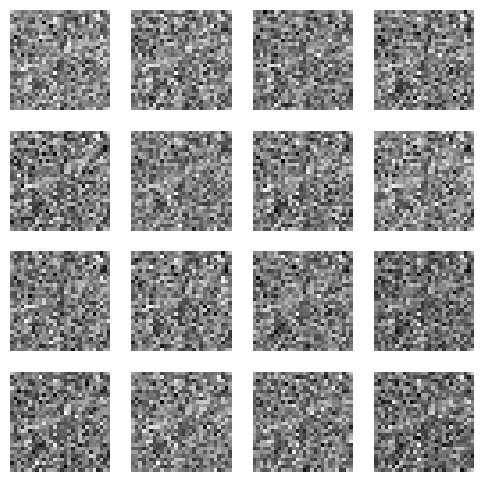

In [9]:
show_generated(G)

Epoch 1/100  D=0.0209  G=7.6592


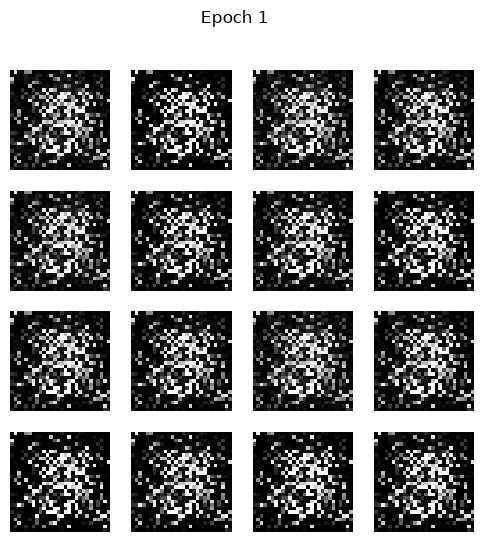

Epoch 2/100  D=0.1216  G=4.0263


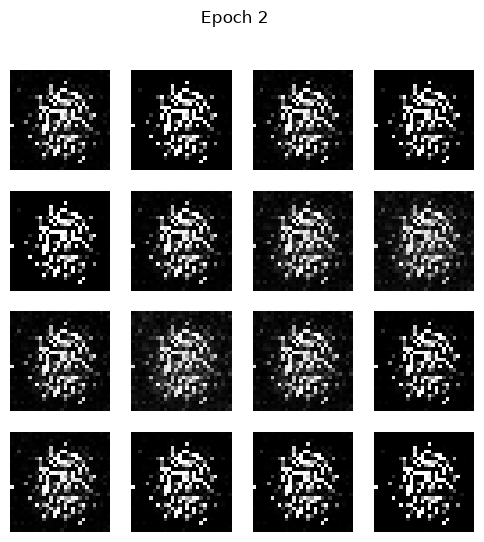

Epoch 3/100  D=0.4249  G=4.4986


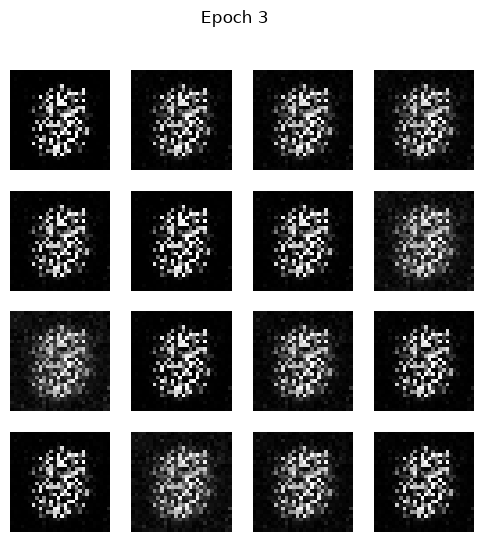

Epoch 4/100  D=1.4800  G=1.5159


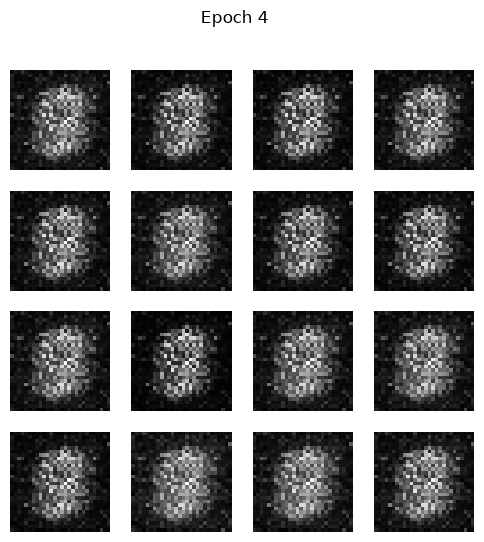

Epoch 5/100  D=0.4962  G=2.0377


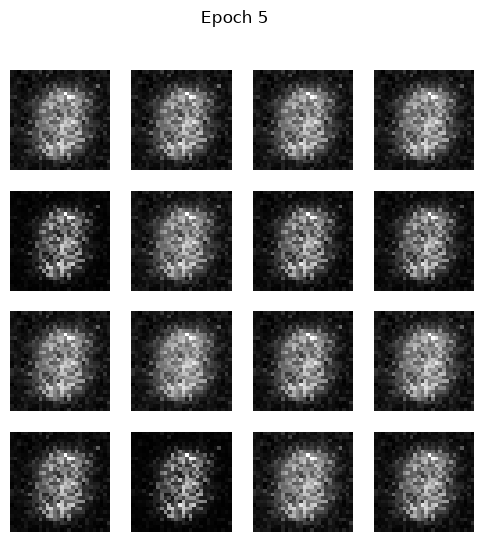

Epoch 6/100  D=0.2295  G=2.8535


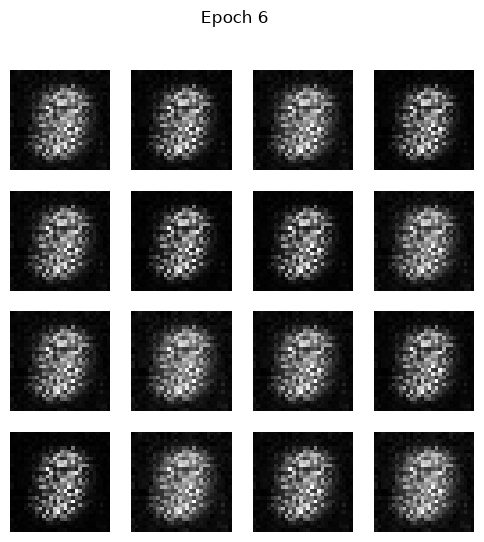

Epoch 7/100  D=0.8903  G=1.5394


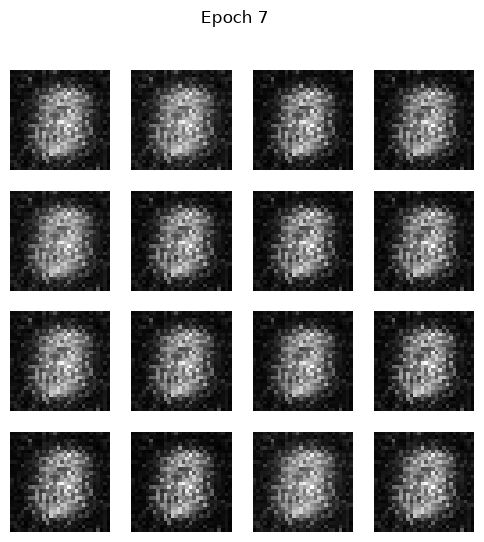

Epoch 8/100  D=0.2906  G=2.4318


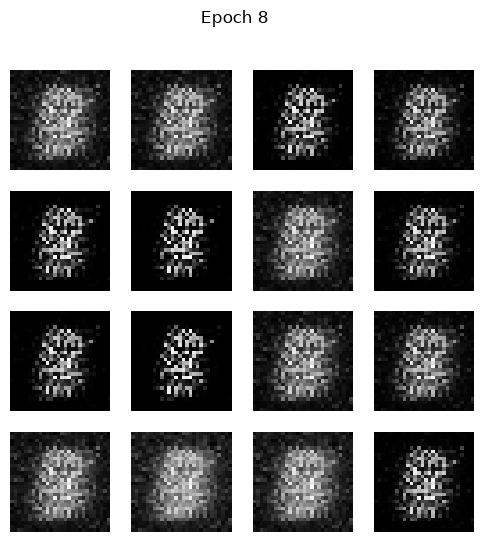

Epoch 9/100  D=0.3718  G=2.2632


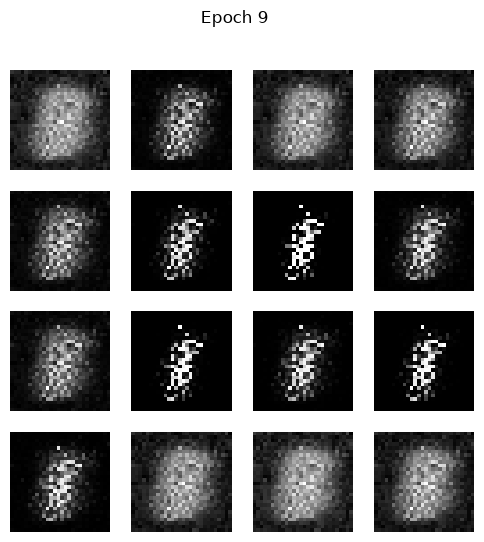

Epoch 10/100  D=0.4050  G=3.7773


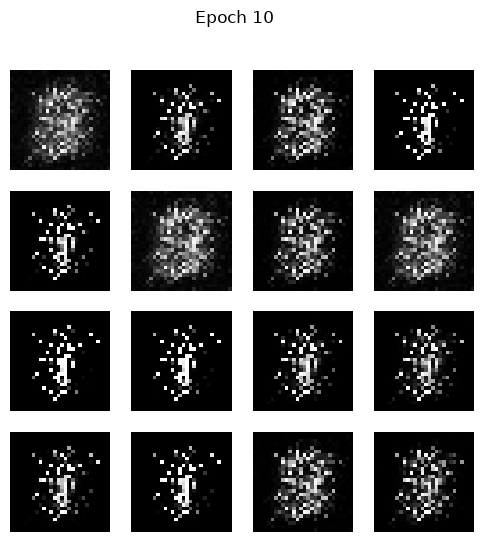

Epoch 11/100  D=0.2628  G=4.6872


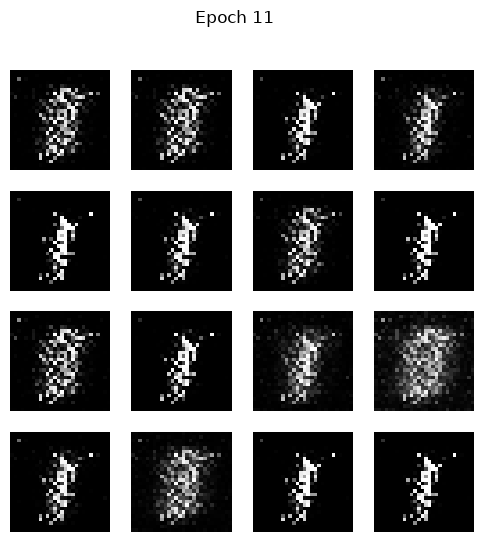

Epoch 12/100  D=0.6453  G=6.4411


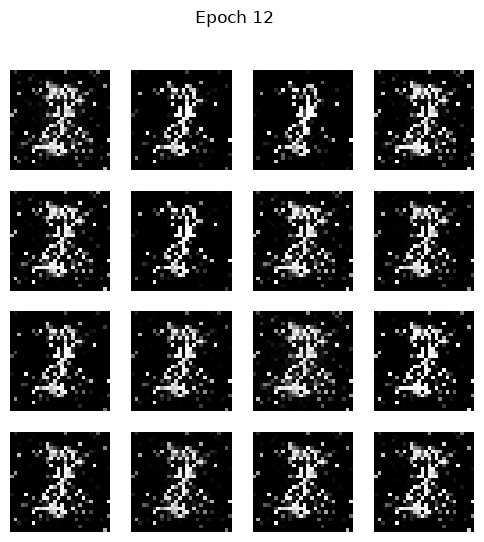

Epoch 13/100  D=0.4124  G=3.3926


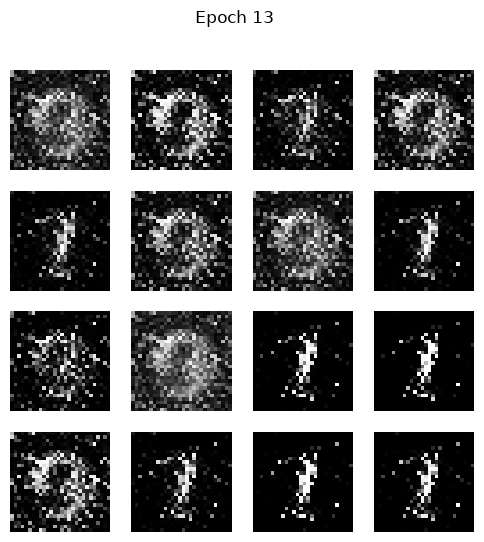

Epoch 14/100  D=0.5300  G=3.3939


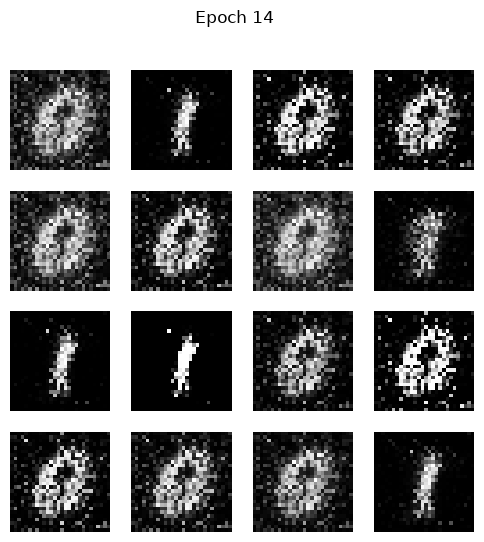

Epoch 15/100  D=0.4798  G=3.3068


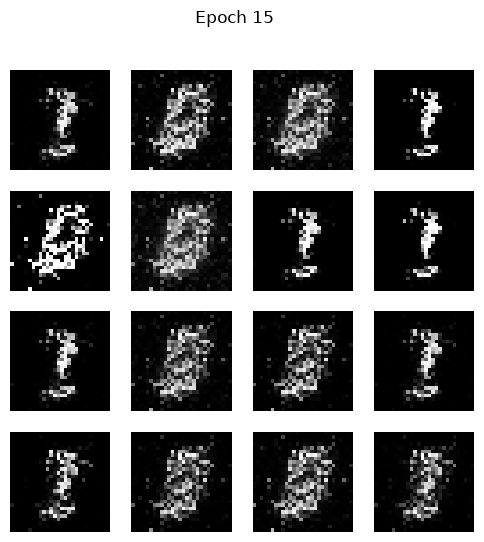

Epoch 16/100  D=0.2705  G=3.7281


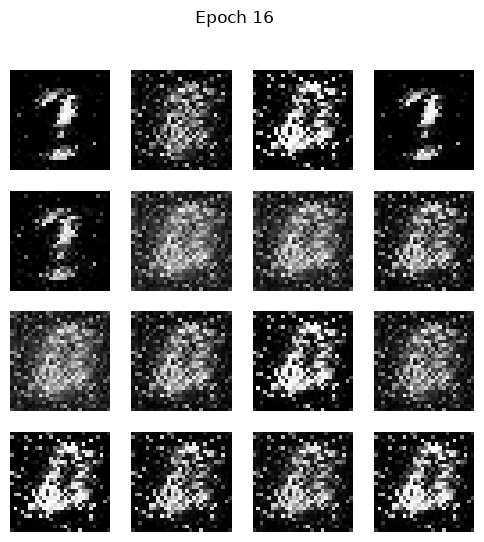

Epoch 17/100  D=0.3728  G=3.2000


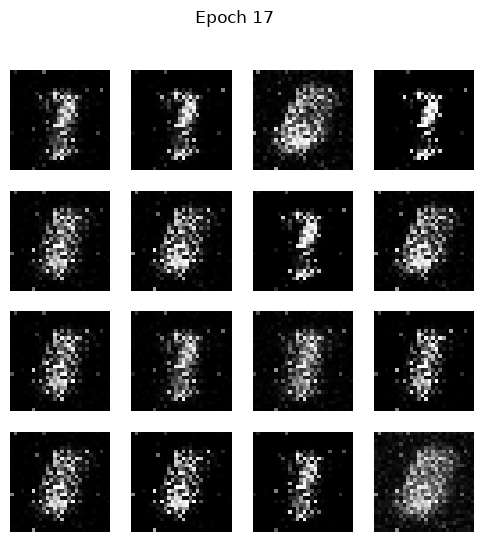

Epoch 18/100  D=0.3781  G=3.7960


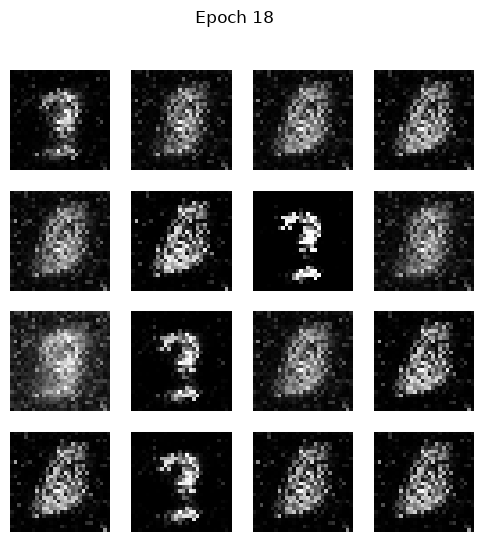

Epoch 19/100  D=0.6179  G=4.5912


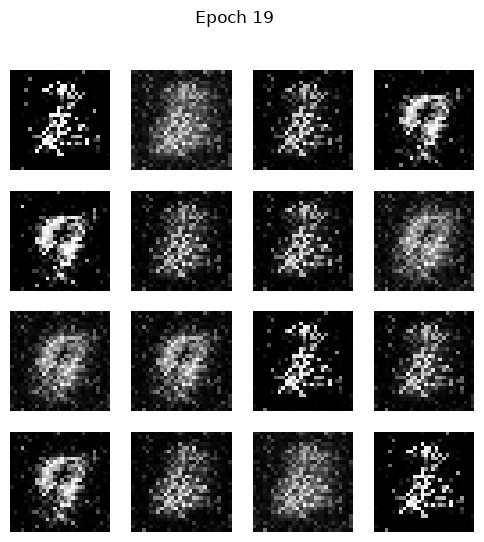

Epoch 20/100  D=0.7260  G=2.1976


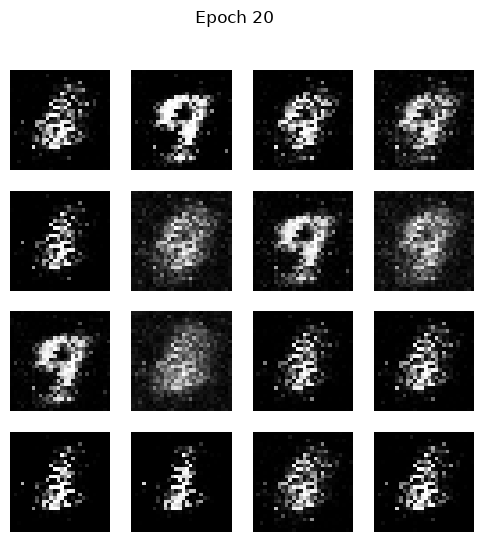

Epoch 21/100  D=0.3092  G=3.8030


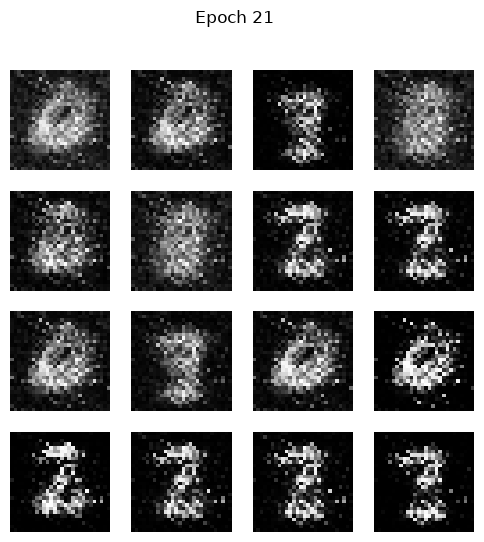

Epoch 22/100  D=0.3516  G=3.7204


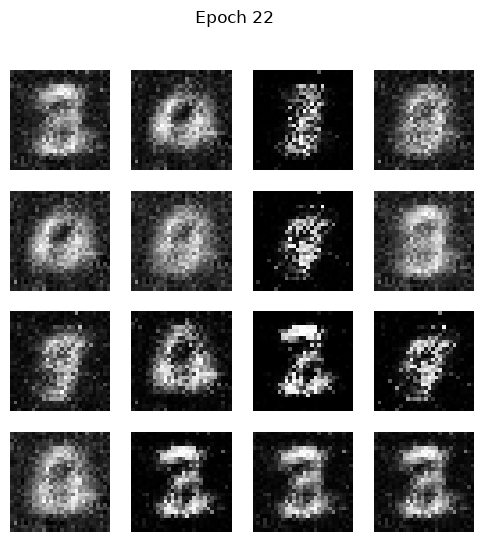

Epoch 23/100  D=0.3058  G=4.0018


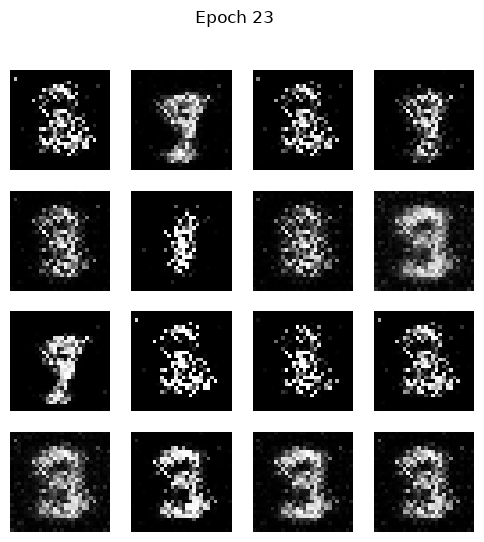

Epoch 24/100  D=0.1793  G=2.9472


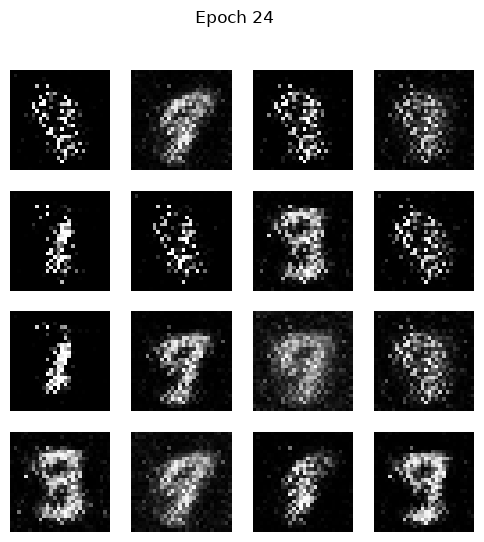

Epoch 25/100  D=0.6439  G=2.8812


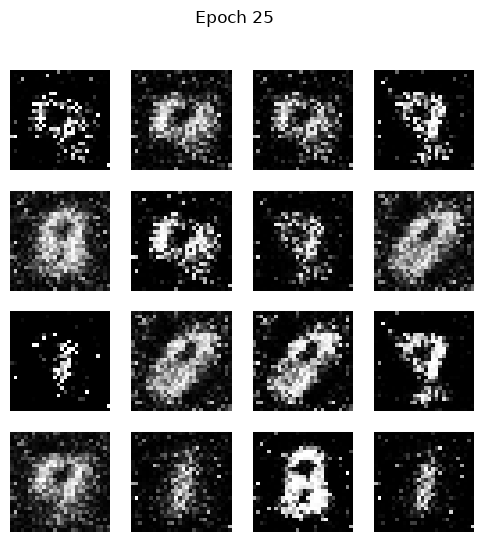

Epoch 26/100  D=0.3914  G=3.9135


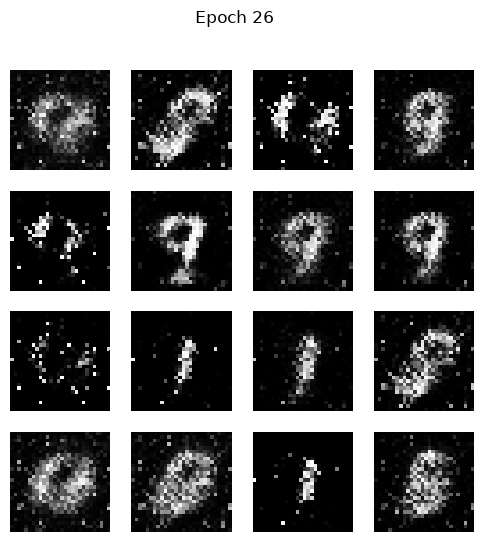

Epoch 27/100  D=0.5970  G=2.6184


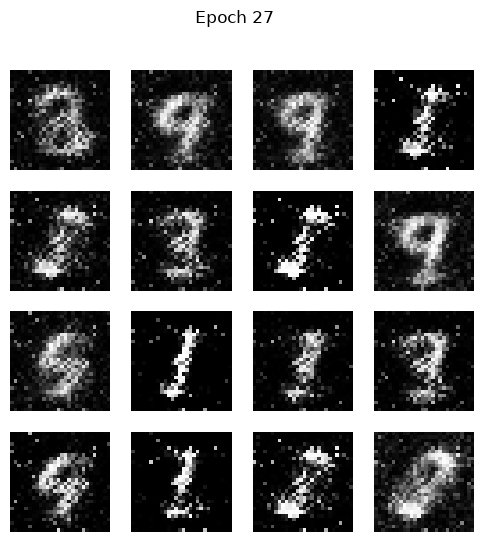

Epoch 28/100  D=1.1668  G=3.7443


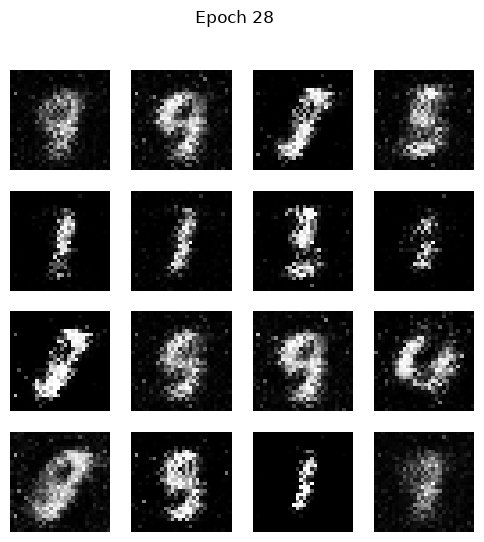

Epoch 29/100  D=0.3779  G=2.2227


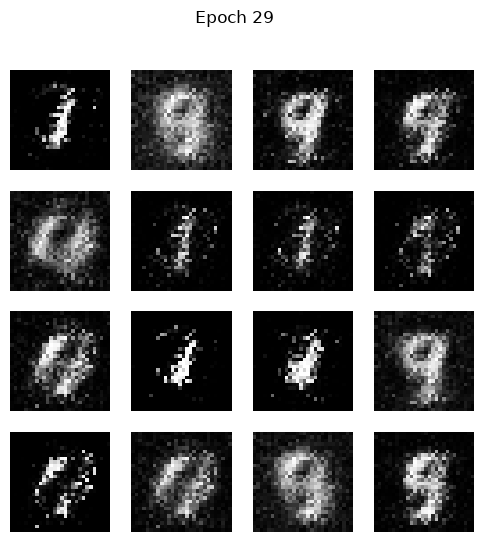

Epoch 30/100  D=0.6165  G=2.6135


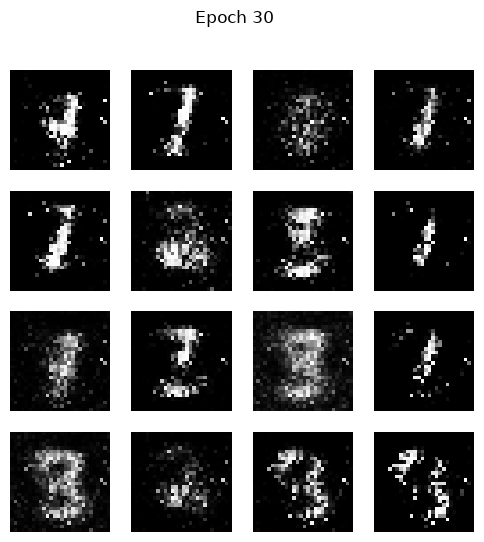

Epoch 31/100  D=0.5005  G=3.7169


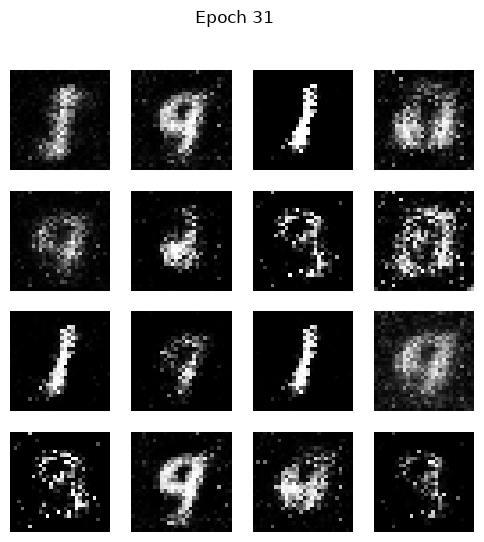

Epoch 32/100  D=0.3039  G=3.7922


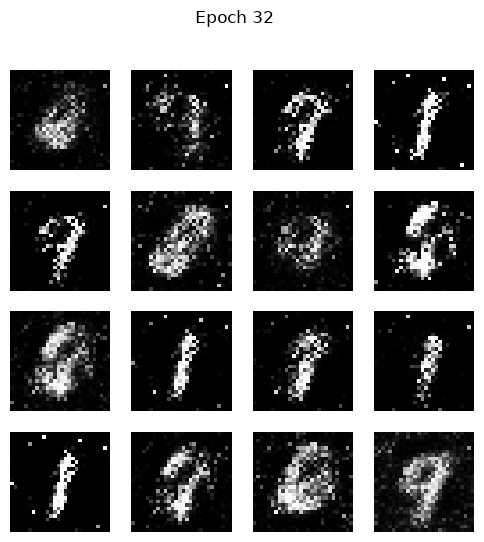

Epoch 33/100  D=0.7256  G=3.3861


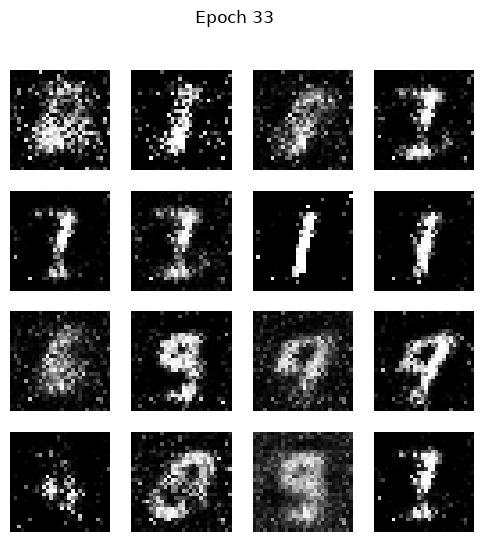

Epoch 34/100  D=0.3995  G=3.6327


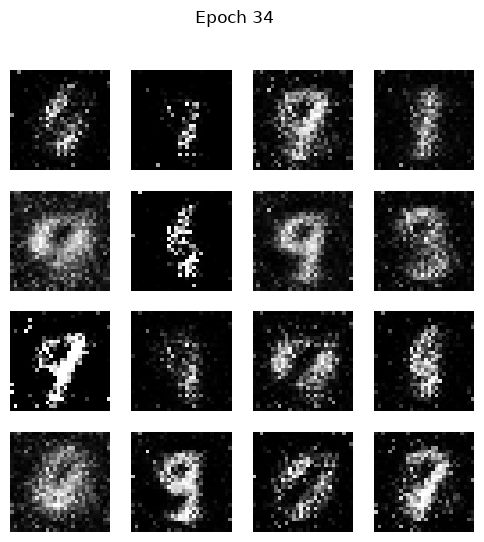

Epoch 35/100  D=0.3517  G=3.0938


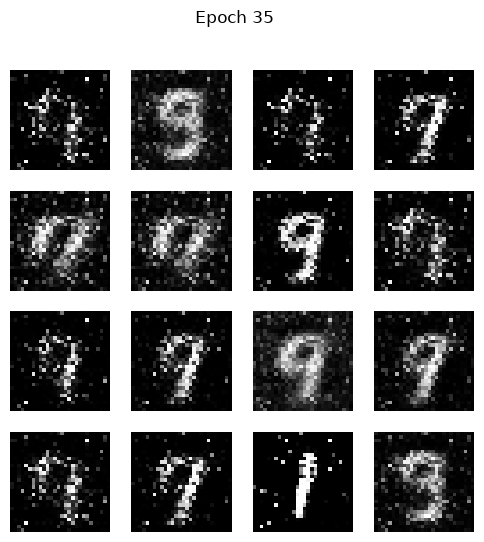

Epoch 36/100  D=0.1886  G=6.4161


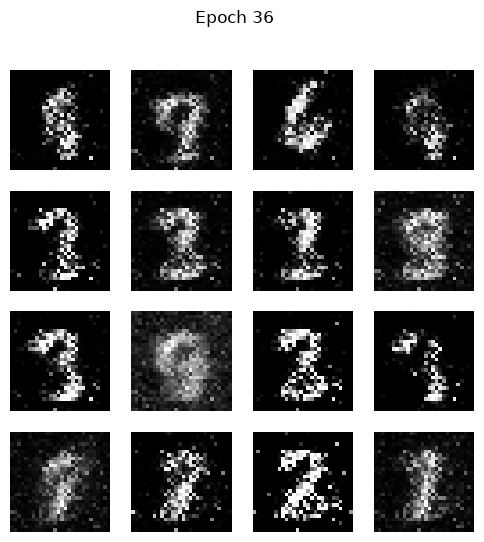

Epoch 37/100  D=0.1892  G=6.3054


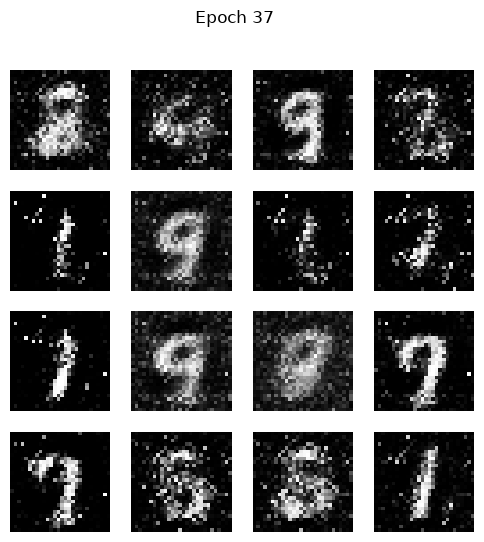

Epoch 38/100  D=0.2266  G=3.5986


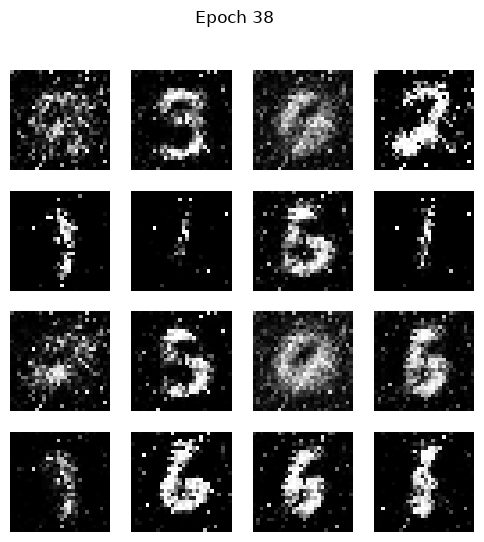

Epoch 39/100  D=0.2723  G=3.5985


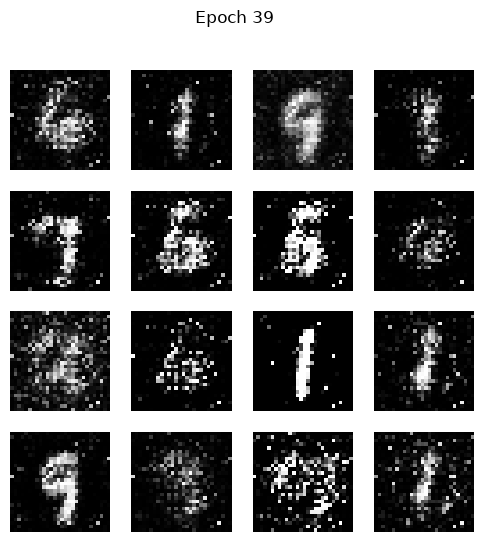

Epoch 40/100  D=0.2504  G=4.6066


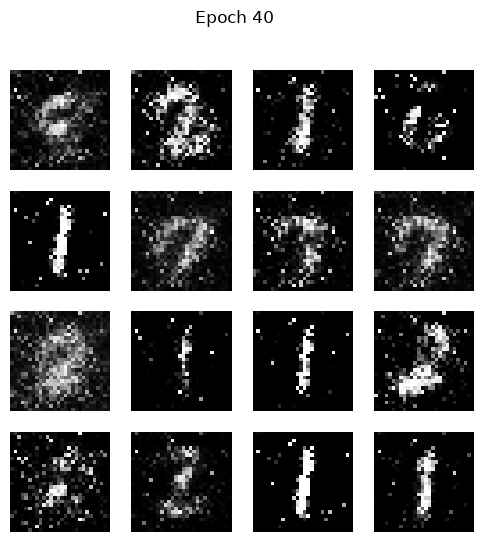

Epoch 41/100  D=0.2101  G=4.5578


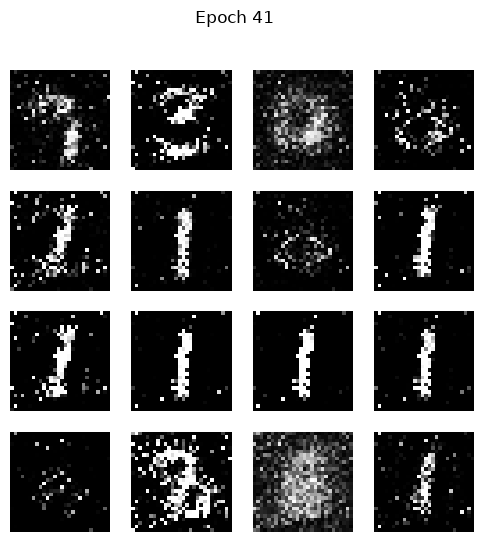

Epoch 42/100  D=0.3207  G=4.6854


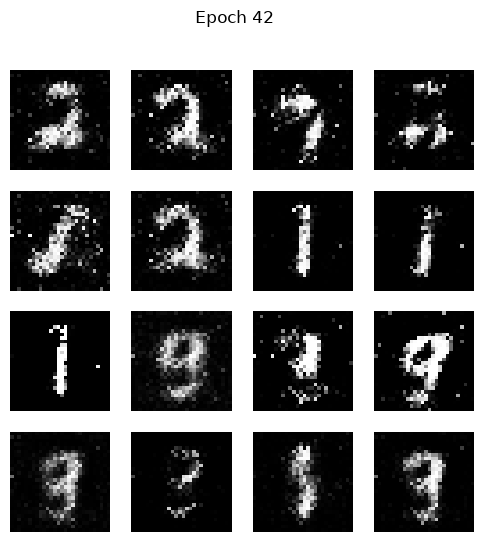

Epoch 43/100  D=0.2265  G=4.8442


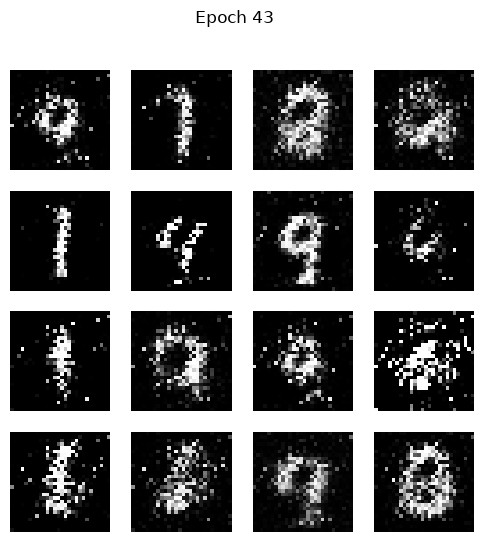

Epoch 44/100  D=0.3437  G=4.2903


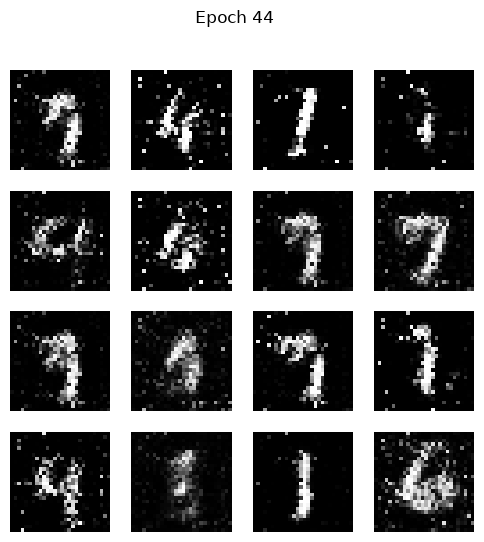

Epoch 45/100  D=0.2783  G=3.5993


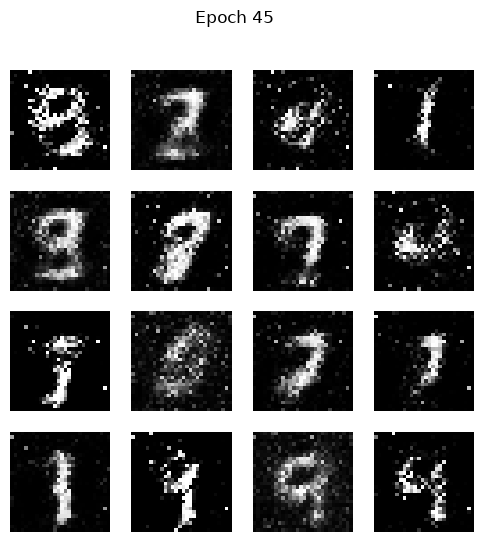

Epoch 46/100  D=0.2399  G=3.9573


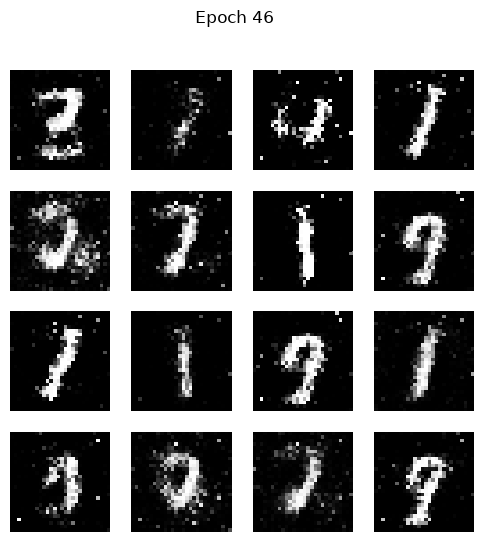

Epoch 47/100  D=0.5614  G=2.8997


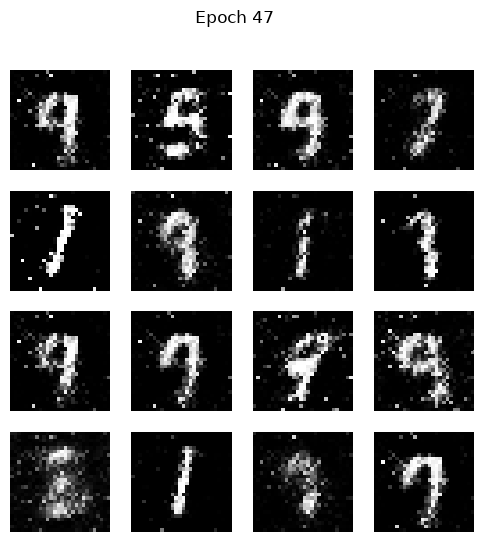

Epoch 48/100  D=0.5193  G=3.1791


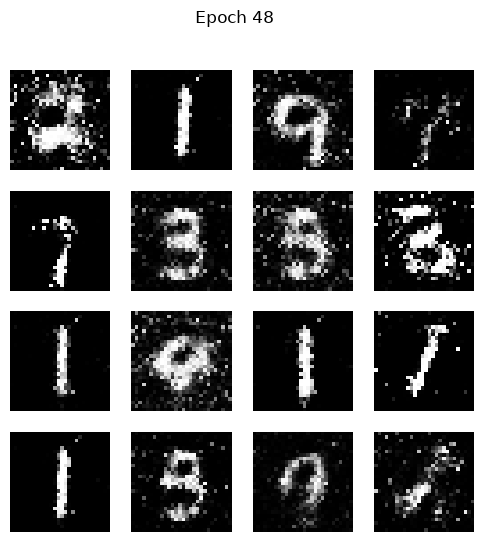

Epoch 49/100  D=0.3500  G=4.0404


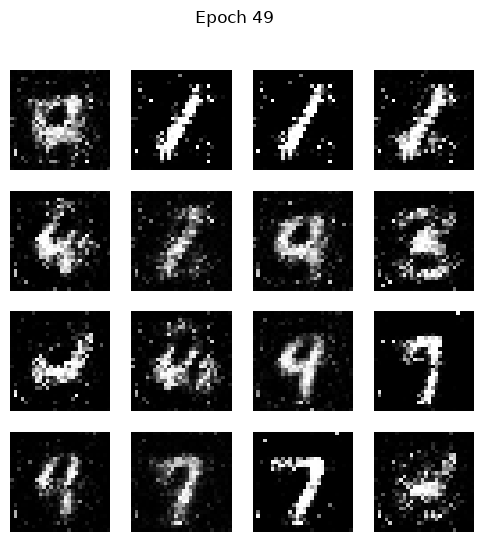

Epoch 50/100  D=0.4568  G=2.6139


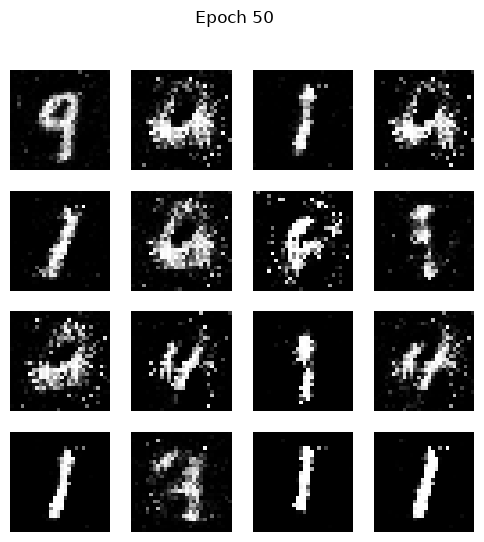

Epoch 51/100  D=0.5423  G=2.4469


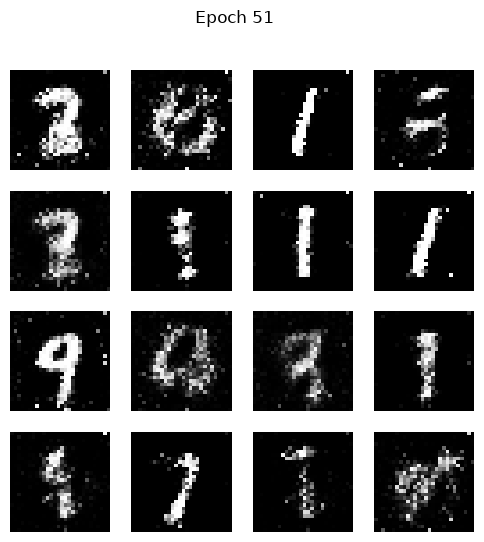

Epoch 52/100  D=0.6749  G=4.0374


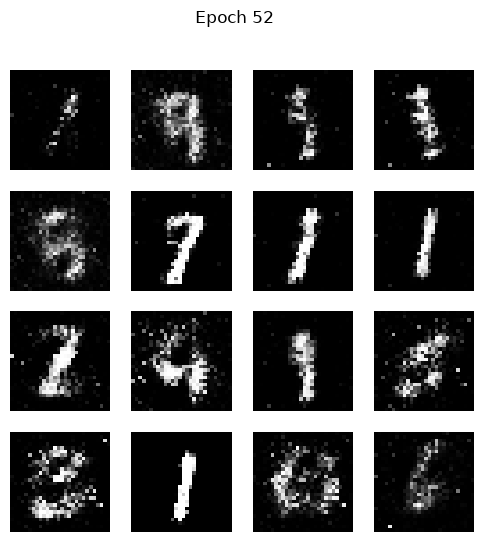

Epoch 53/100  D=0.4871  G=2.1440


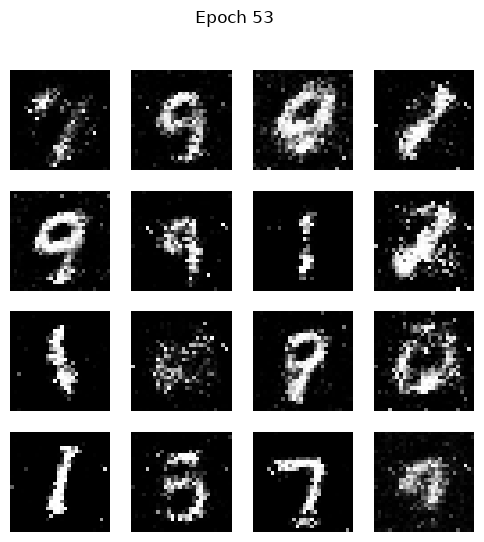

Epoch 54/100  D=0.3585  G=2.8852


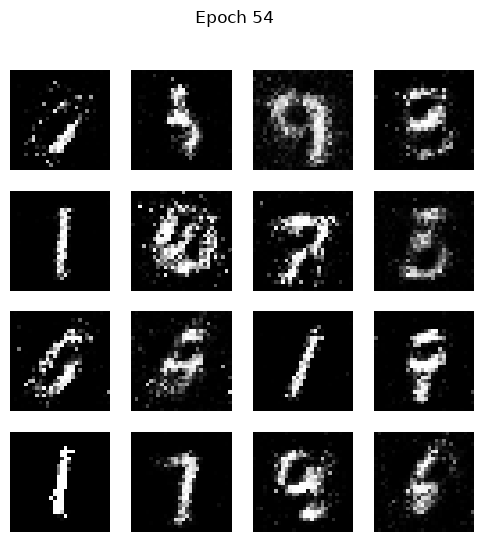

Epoch 55/100  D=0.5658  G=2.4471


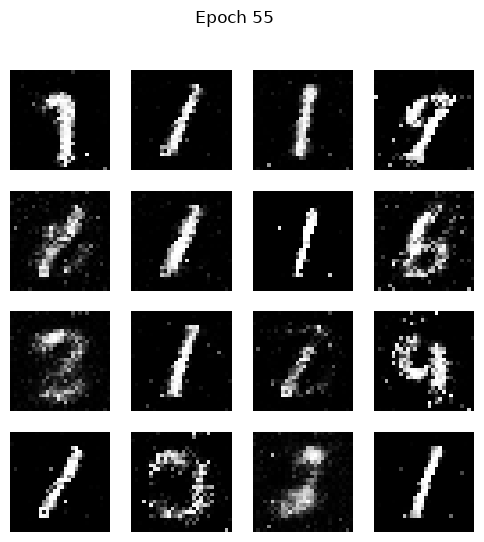

Epoch 56/100  D=0.6164  G=2.6881


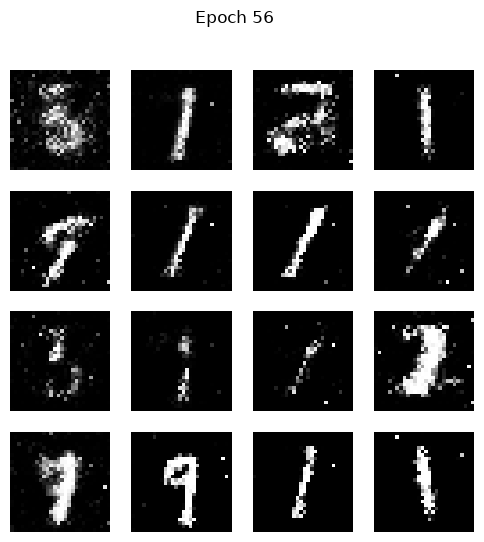

Epoch 57/100  D=0.5810  G=2.2832


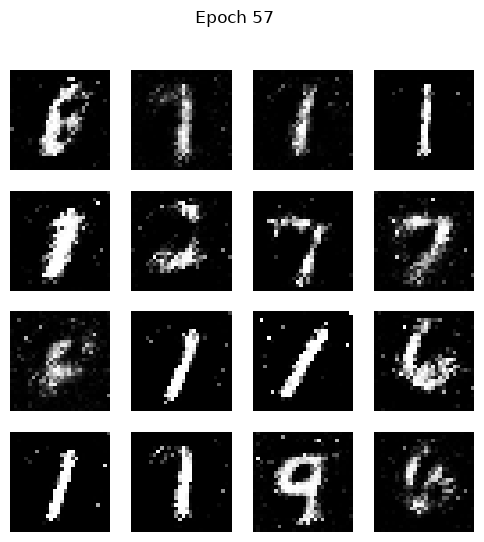

Epoch 58/100  D=0.6953  G=2.5557


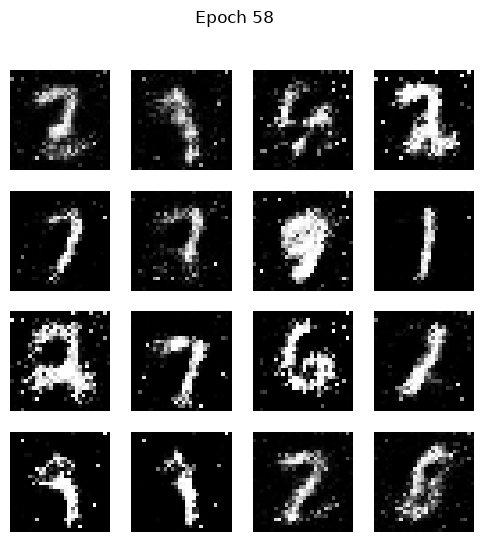

Epoch 59/100  D=0.3826  G=3.0095


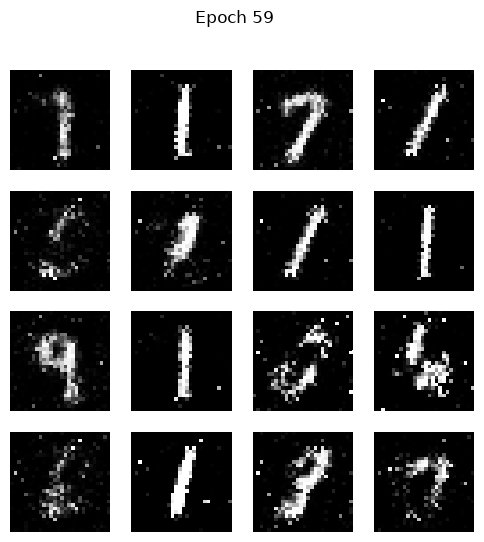

Epoch 60/100  D=0.4755  G=3.7597


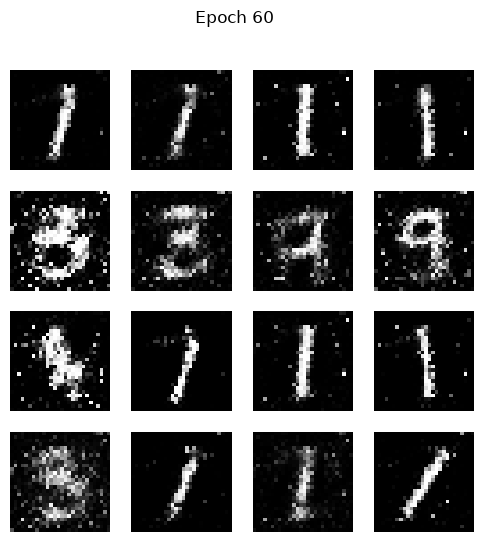

Epoch 61/100  D=0.5857  G=2.6234


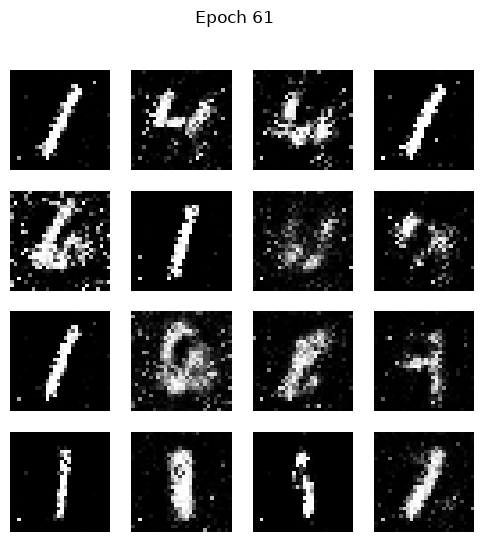

Epoch 62/100  D=0.5196  G=3.0585


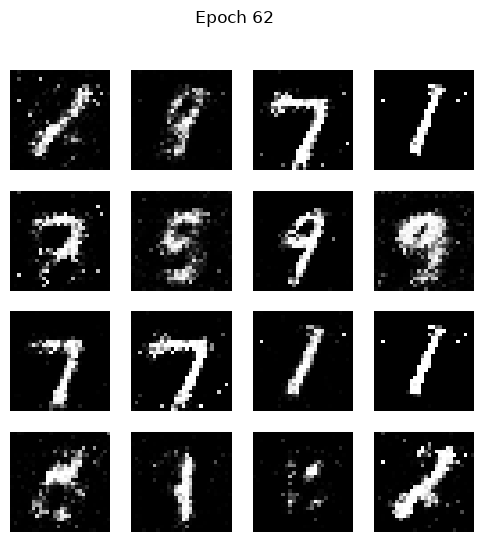

Epoch 63/100  D=0.5523  G=2.4448


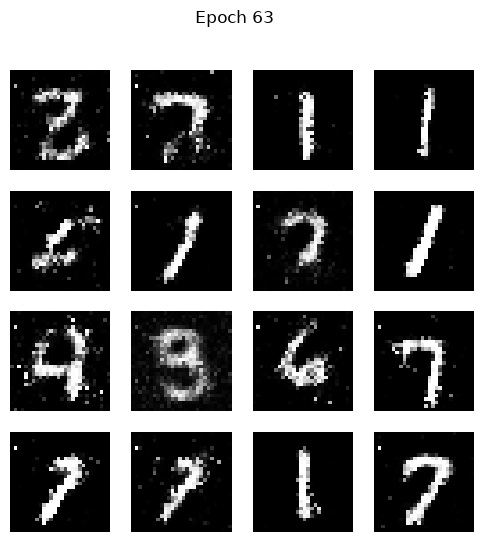

Epoch 64/100  D=0.5506  G=2.5011


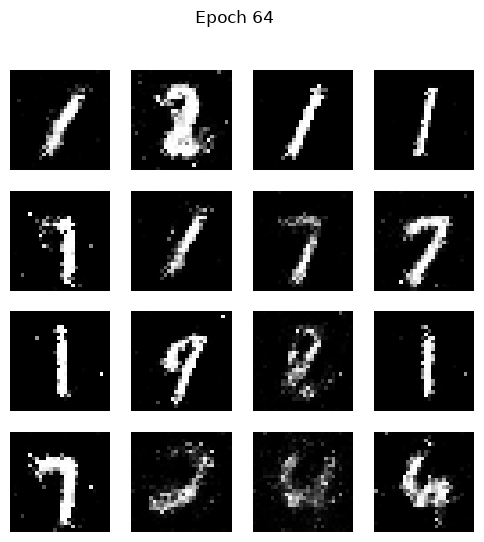

Epoch 65/100  D=0.5783  G=2.3574


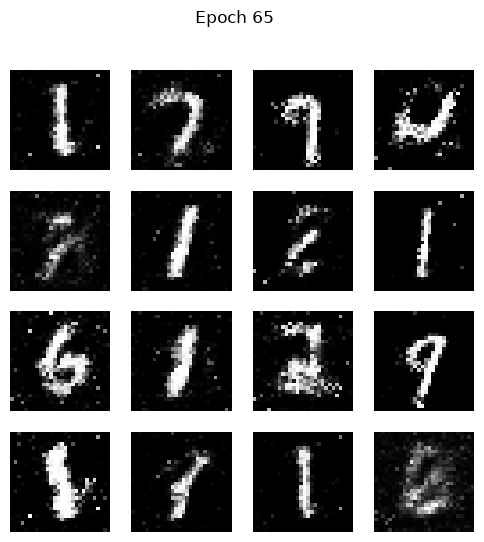

Epoch 66/100  D=0.5817  G=2.7751


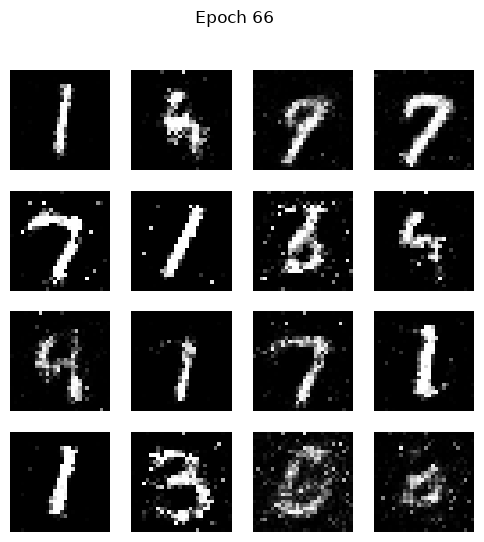

Epoch 67/100  D=0.7171  G=2.7901


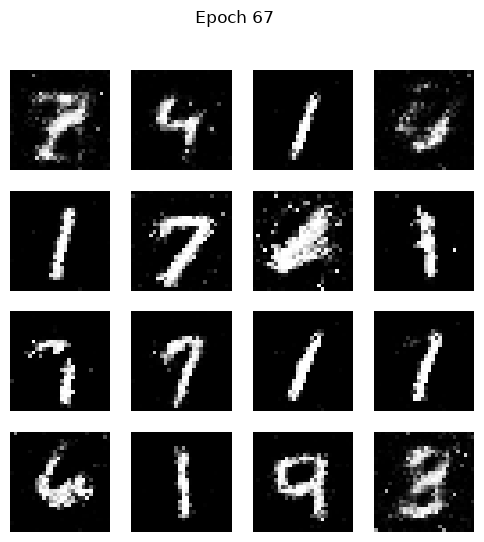

Epoch 68/100  D=0.5436  G=2.7795


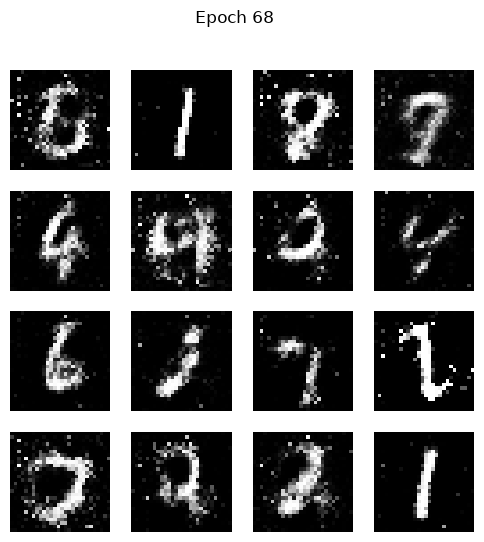

Epoch 69/100  D=0.5846  G=2.6815


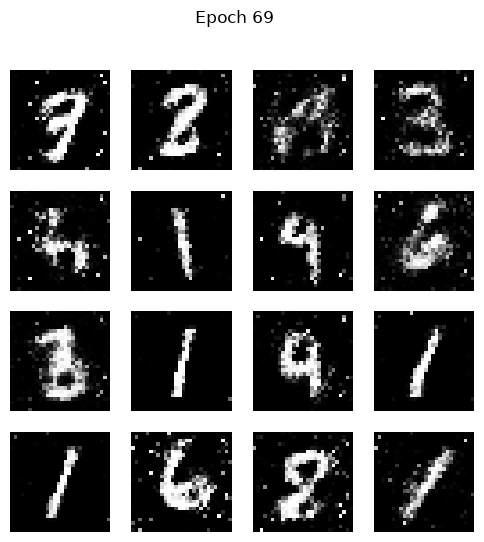

Epoch 70/100  D=0.5358  G=1.8100


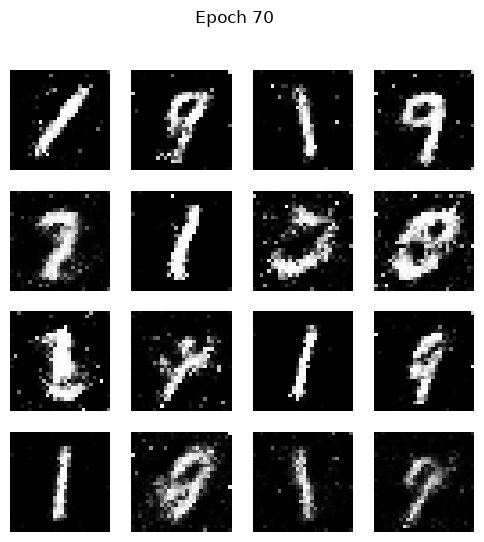

Epoch 71/100  D=0.5470  G=3.5181


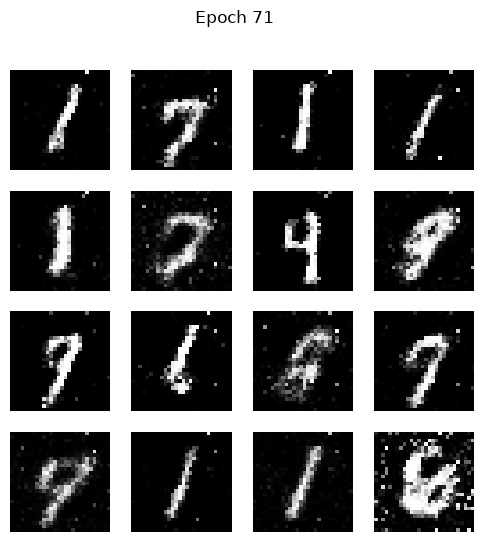

Epoch 72/100  D=0.4974  G=3.0078


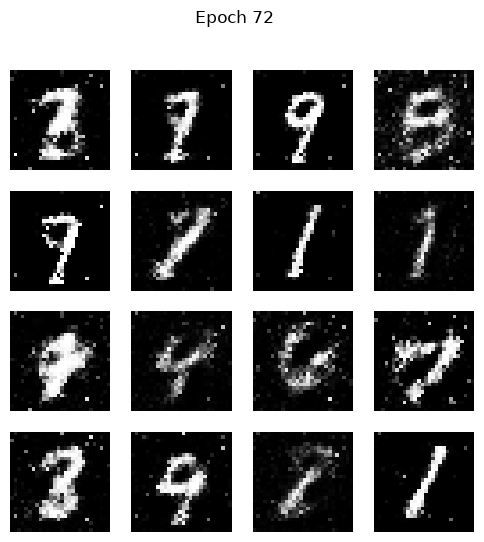

Epoch 73/100  D=0.5610  G=3.3998


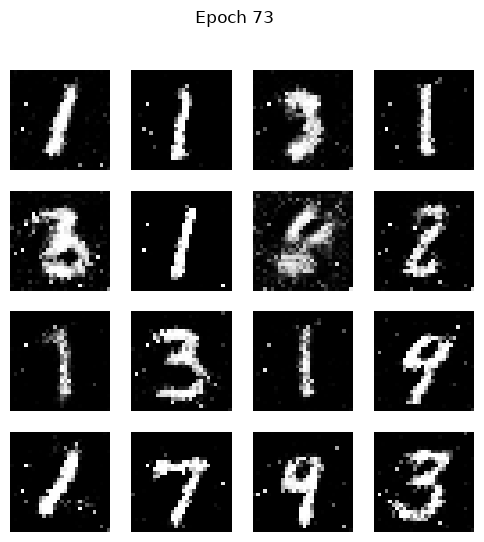

Epoch 74/100  D=0.6239  G=2.8403


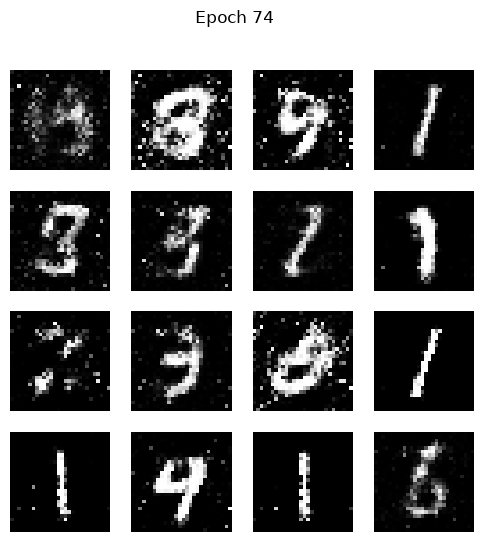

Epoch 75/100  D=0.6604  G=2.3085


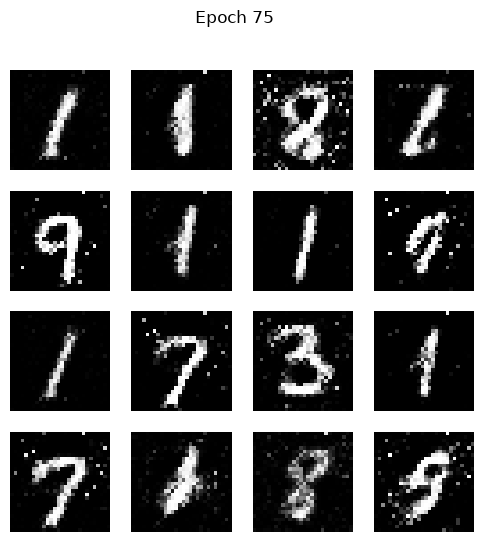

Epoch 76/100  D=0.6586  G=1.8407


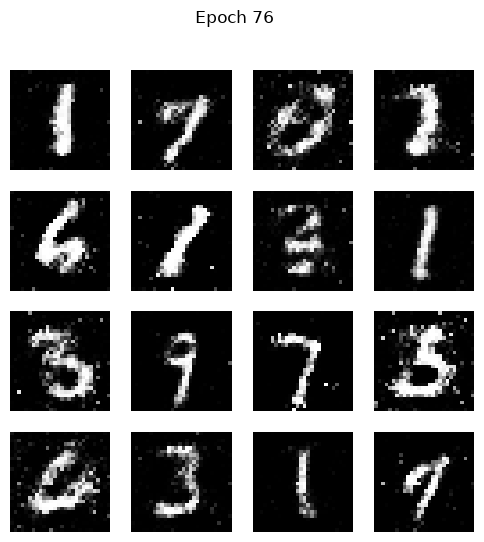

Epoch 77/100  D=0.6472  G=2.0641


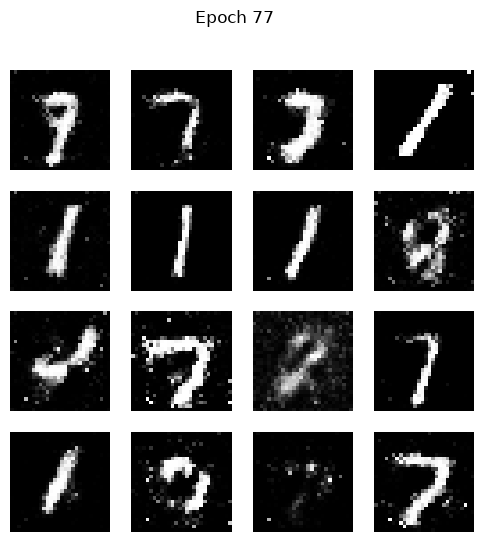

Epoch 78/100  D=0.7860  G=2.3197


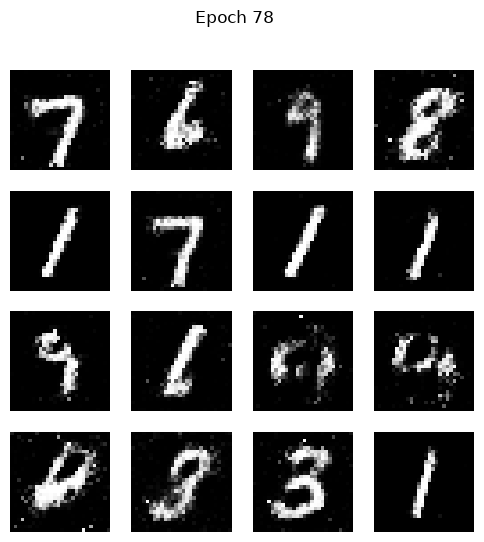

Epoch 79/100  D=0.6675  G=2.4476


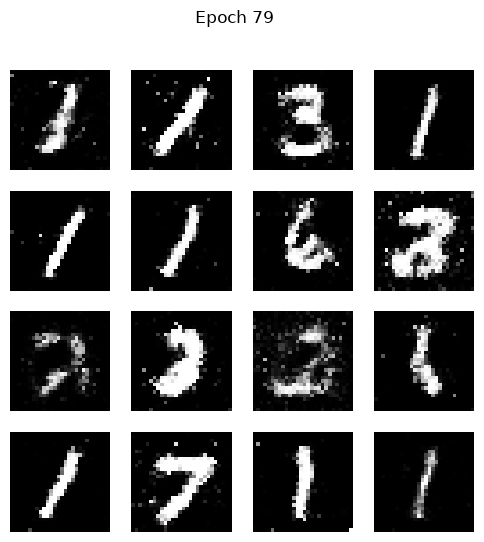

Epoch 80/100  D=0.6110  G=2.0457


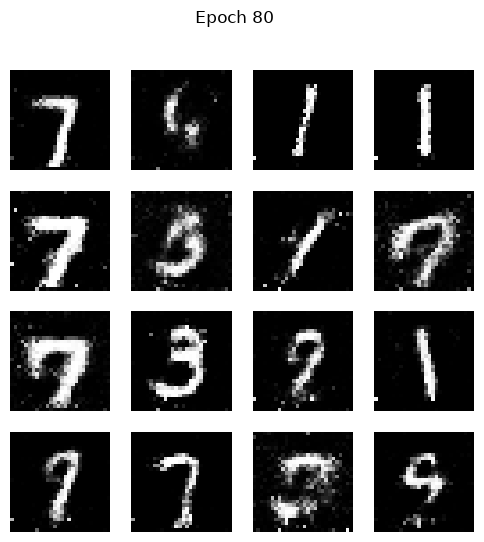

Epoch 81/100  D=0.7804  G=2.4498


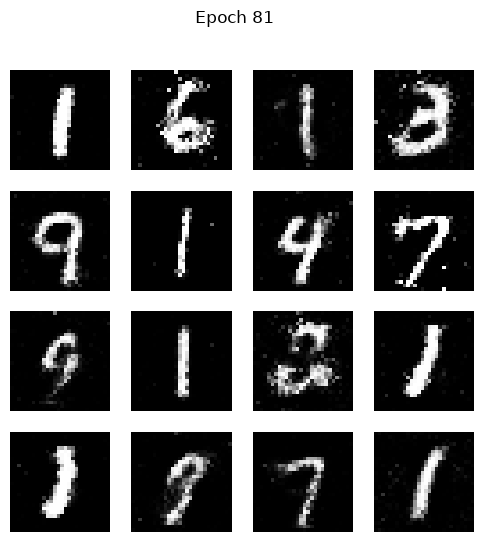

Epoch 82/100  D=0.8080  G=2.0037


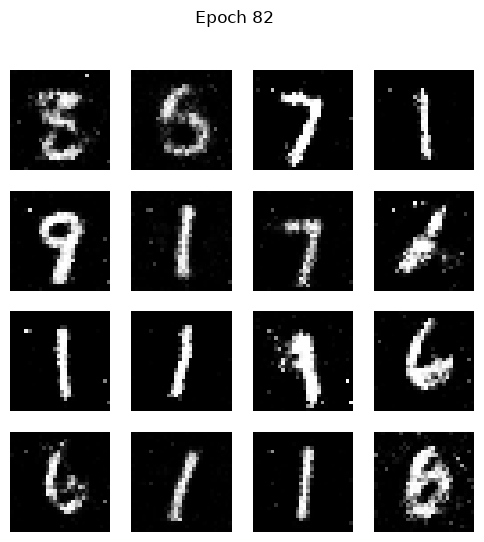

Epoch 83/100  D=0.9181  G=1.8570


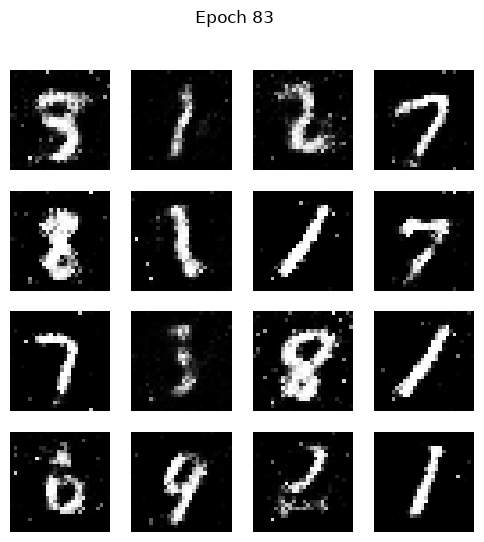

Epoch 84/100  D=0.6984  G=2.1767


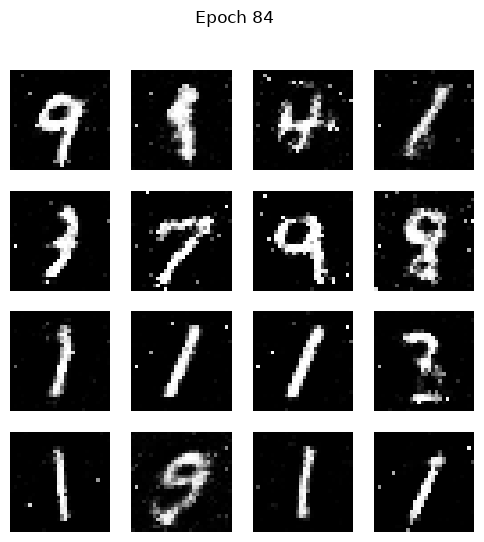

Epoch 85/100  D=0.8083  G=1.9563


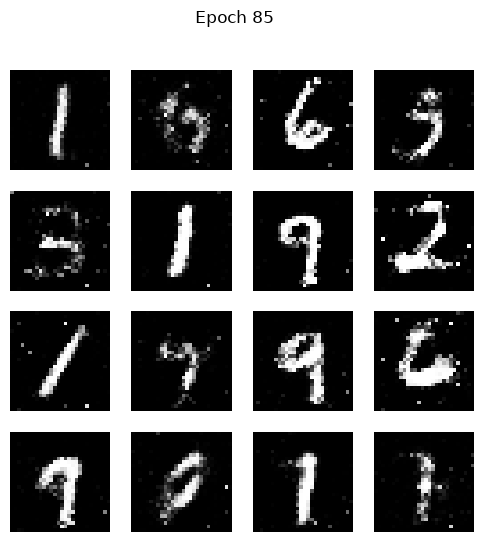

Epoch 86/100  D=0.8618  G=1.8551


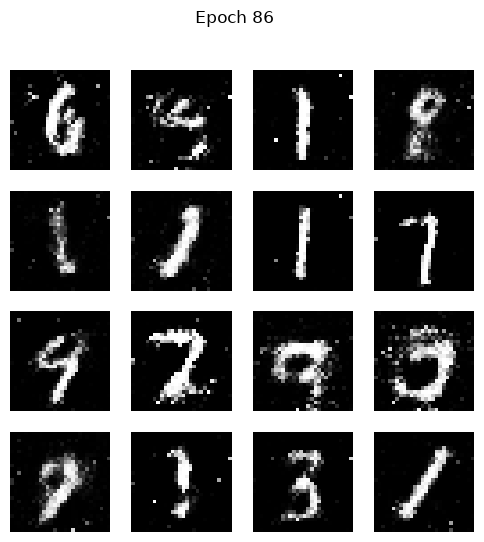

Epoch 87/100  D=0.5541  G=2.2029


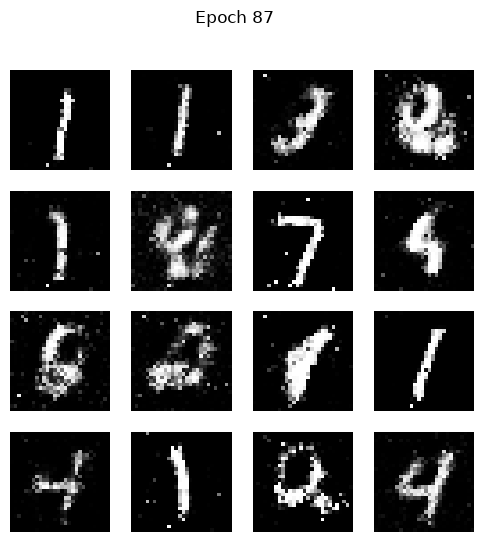

Epoch 88/100  D=0.7375  G=2.0731


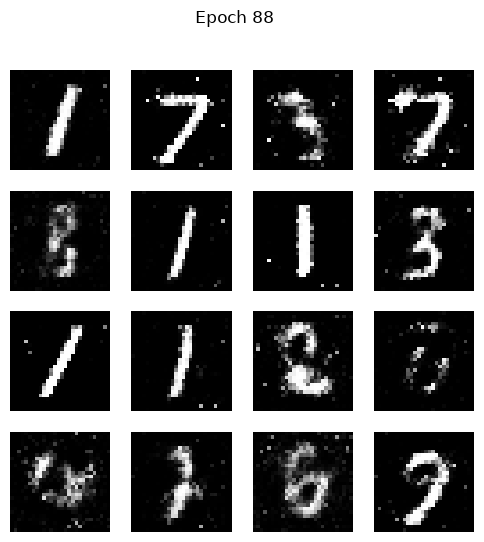

Epoch 89/100  D=0.7606  G=2.0361


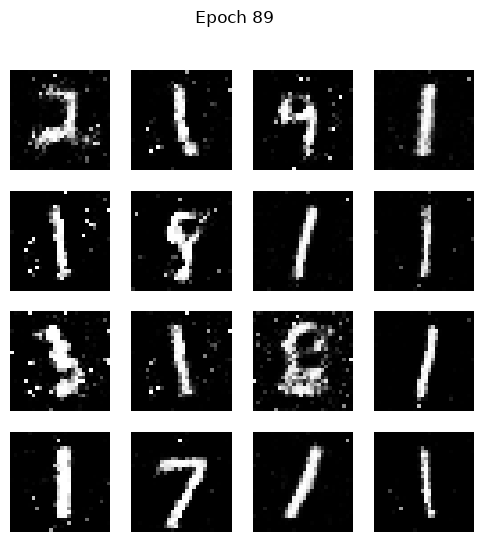

Epoch 90/100  D=0.7426  G=2.6768


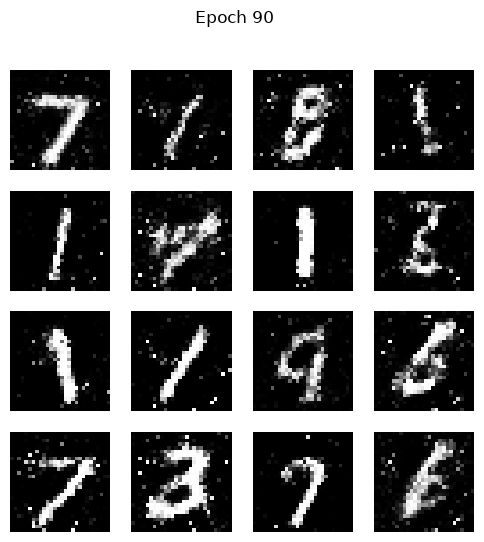

Epoch 91/100  D=0.8155  G=1.9296


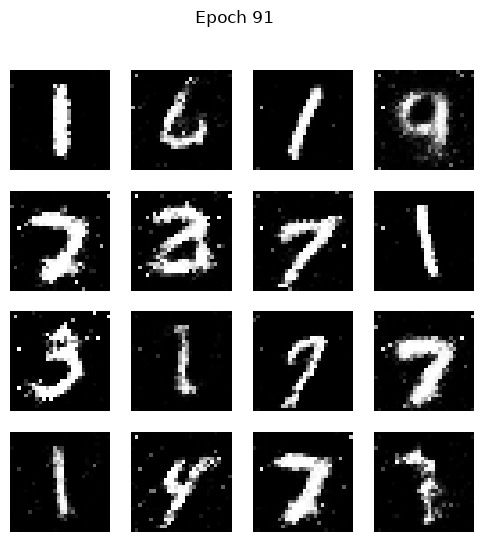

Epoch 92/100  D=0.7310  G=1.9844


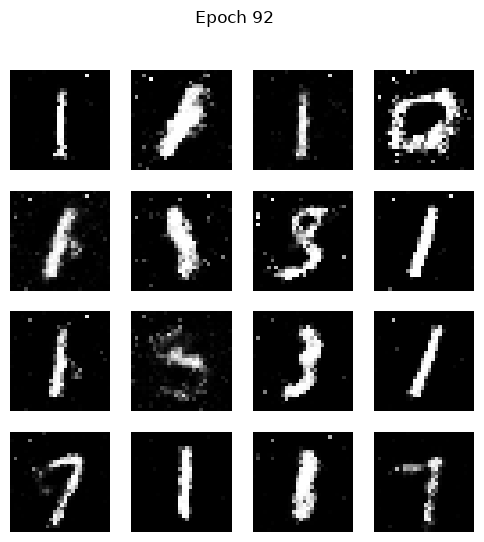

Epoch 93/100  D=0.5870  G=2.5973


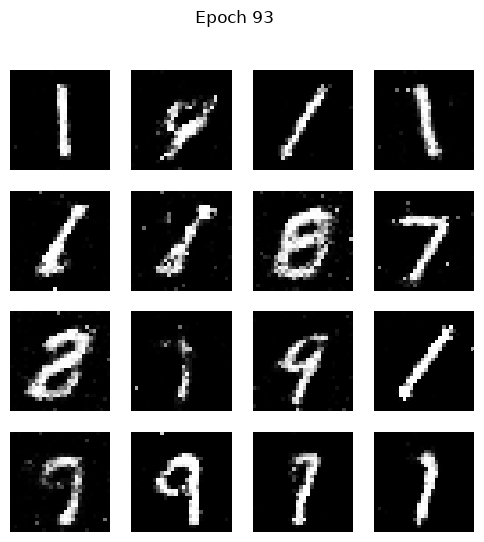

Epoch 94/100  D=0.9760  G=2.3396


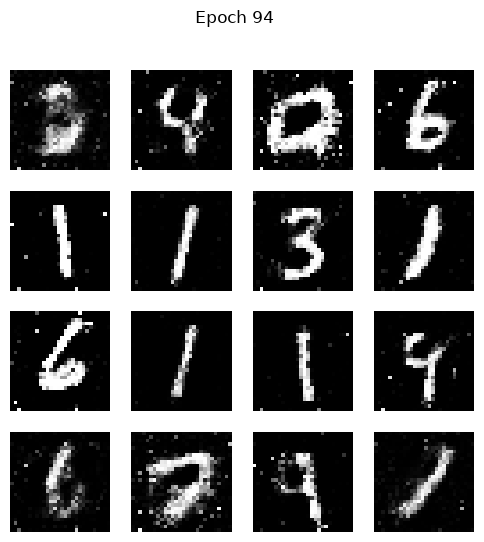

Epoch 95/100  D=0.8224  G=2.1913


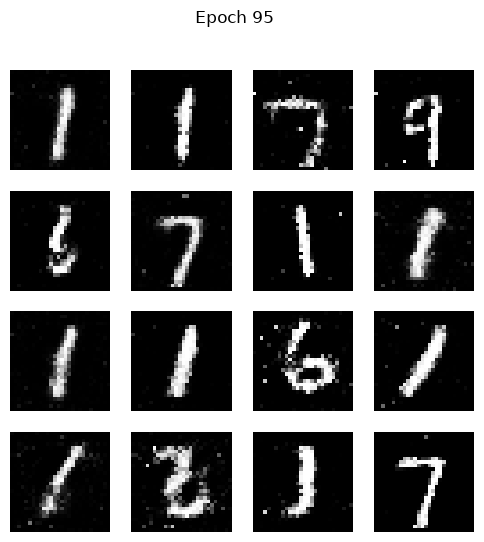

Epoch 96/100  D=0.7992  G=2.1359


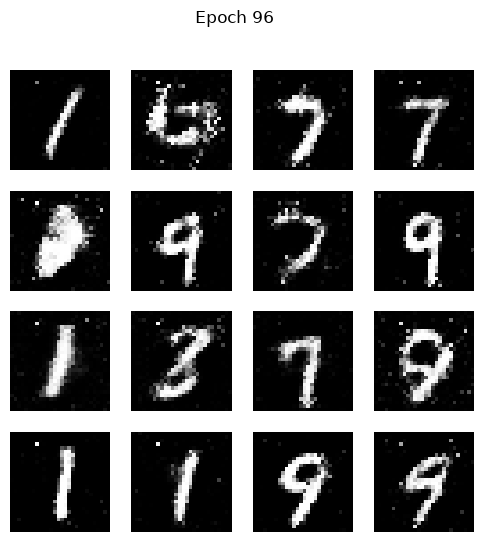

Epoch 97/100  D=0.6572  G=2.1957


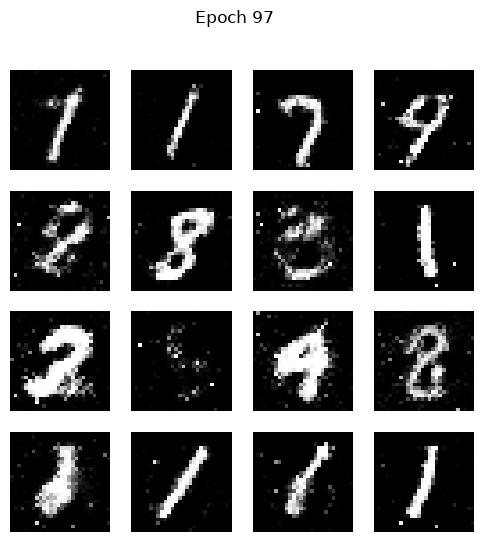

Epoch 98/100  D=0.8831  G=2.1167


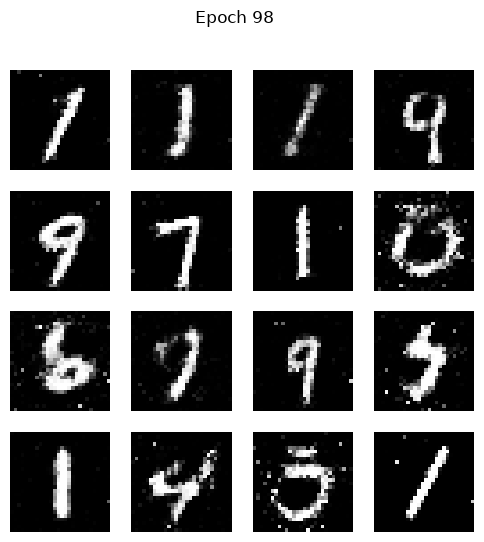

Epoch 99/100  D=0.7335  G=2.4764


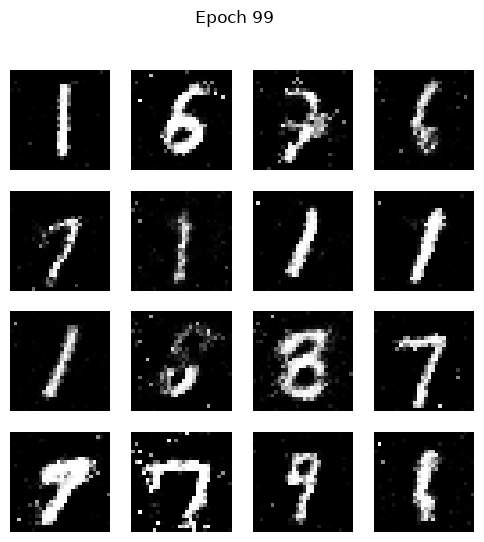

Epoch 100/100  D=1.1197  G=1.9513


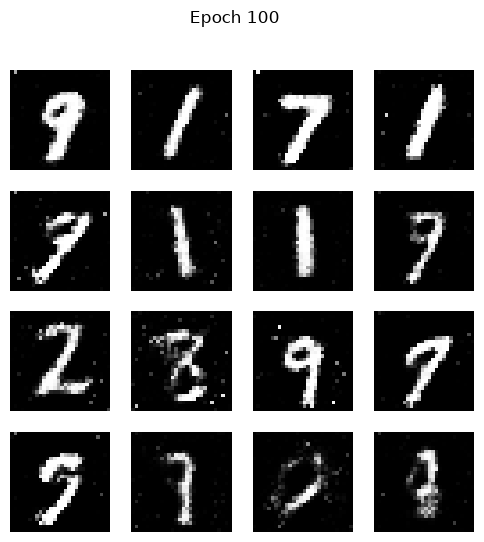

In [10]:
EPOCHS = 100

g_losses = []
d_losses = []

for epoch in range(EPOCHS):
    for real_images, _ in loader:
        batch_size = real_images.size(0)
        real_images = real_images.view(batch_size, -1).to(device)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = G(z)

        d_real = D(real_images)
        d_fake = D(fake_images.detach())

        d_loss = (
            criterion(d_real, real_labels) +
            criterion(d_fake, fake_labels)
        )

        d_optimizer.zero_grad()
        d_loss.backward()
        d_optimizer.step()

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = G(z)

        g_loss = criterion(D(fake_images), real_labels)

        g_optimizer.zero_grad()
        g_loss.backward()
        g_optimizer.step()

    g_losses.append(g_loss.item())
    d_losses.append(d_loss.item())

    print(f"Epoch {epoch+1}/{EPOCHS}  D={d_loss.item():.4f}  G={g_loss.item():.4f}")
    show_generated(G, epoch=epoch+1)


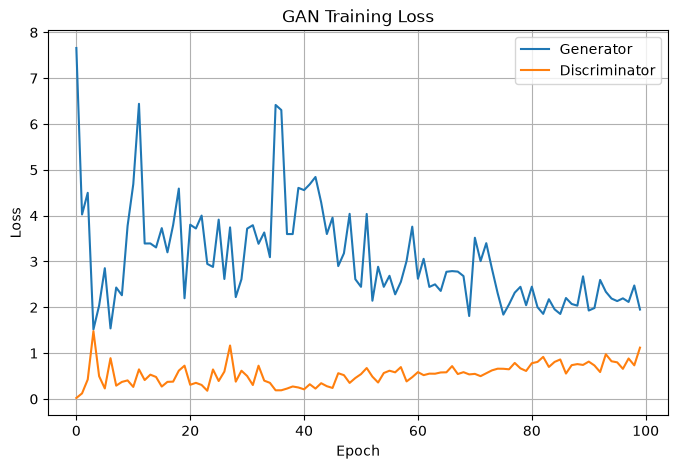

In [11]:
plt.figure(figsize=(8,5))
plt.plot(g_losses,label="Generator")
plt.plot(d_losses,label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()


## Student Experiment

Run the notebook three times using latent dimensions 20, 100, and 200. Record final losses and compare generated image quality.

## Reflection Questions

1. Why does the generator use random noise?
2. What role does the discriminator play?
3. When do digits become recognizable?
4. What is mode collapse?
5. What effect did latent dimension have on image diversity?
6. How does a GAN differ from a CNN classifier?